## 0. Дайте відповідь на запитання:
1. Чому для заповнення пропусків було обрано метод kNN?
2. Чому при тренуванні лінійної регресії train і val порівнюються лише на основі MSE, а після тренування на основі багатьох функцій? Проекспериментуйте в межах тренування з вибором функції і поділіться результатами.
3. Які висновки після клітинки 2.6 в демо Ви можете зробити?
4. Поясни для чого потрібен baseline в лінійній регресії і як він вираховується? Що є baseline для нейронної мережі?
5. Продемонструй дію всіх функцій активації на графіку функцій, згенерувавши 1000 випадкових значень Х і порахувавши для них Y через ці функції.
6. Яким чином в нейронній мережі утворилася така кількість параметрів, яка вказана після виконання 3.3?
7. Чи оптимально вибрано кількість епох в 3.5?

### 0.1 Мої відповіді:


1.   KNN шукає найбільш схожі рядки в таблиці і бере середнє значення по них, а не просто середнє по всій колонці. Так дані залишаються більш реалістичними і зберігається зв'язок між ознаками.
2.   Під час тренування оптимізатору потрібна одна гладка функція для обчислення градієнтів, і MSE підходить найкраще, бо сильніше штрафує за великі помилки. А після тренування ми дивимось на MAE, RMSE та R², щоб зрозуміти реальну похибку у звичних одиницях виміру і оцінити загальну точність моделі. Якщо при навчанні замінити MSE на L1Loss або Huber, модель менше реагує на викиди і MAE трохи падає, але MSE та R² стають трохи гіршими.

1.   Оскільки ми попередньо стандартизували ознаки, за величиною ваг можна одразу бачити, які колонки найбільше впливають на прогноз, а які майже не важливі. Плюс або мінус біля ваги показує, збільшує ця ознака цільову змінну чи зменшує.
1.   Baseline у лінійній регресії - це найпростіший орієнтир, коли модель просто завжди видає середнє значення таргету з тренувальної вибірки. Якщо наша модель працює краще за просте вгадування середнього, значить вона справді вчиться. А для нейромережі таким baseline стає вже сама лінійна регресія - нейромережа має сенс лише тоді, коли дає кращі метрики, ніж проста лінійна модель.

1.   Графік із дією функцій активації на 1000 випадкових значеннях X наведено у коді нижче — на ньому видно, що ReLU зануляє всі від'ємні значення, Sigmoid затискає вихід між 0 і 1, Tanh між -1 і 1, а LeakyReLU та ELU залишають невеликий нахил для від'ємних чисел.

2.   Кількість параметрів у кожному лінійному шарі рахується просто: кількість входів множиться на кількість нейронів у шарі - це ваги, плюс додається ще стільки ж параметрів зсуву bias, по одному на кожен нейрон. Функції активації параметрів не мають, тому загальна цифра - це просто сума по всіх шарах Linear.

2.   Судячи з графіка втрат, під кінець тренування крива на валідації вже майже не падає і виходить на плато. Тобто вибраної кількості епох цілком достатньо для збіжності, але навчання можна було б зупинити і трохи раніше, щоб не витрачати зайвий час.







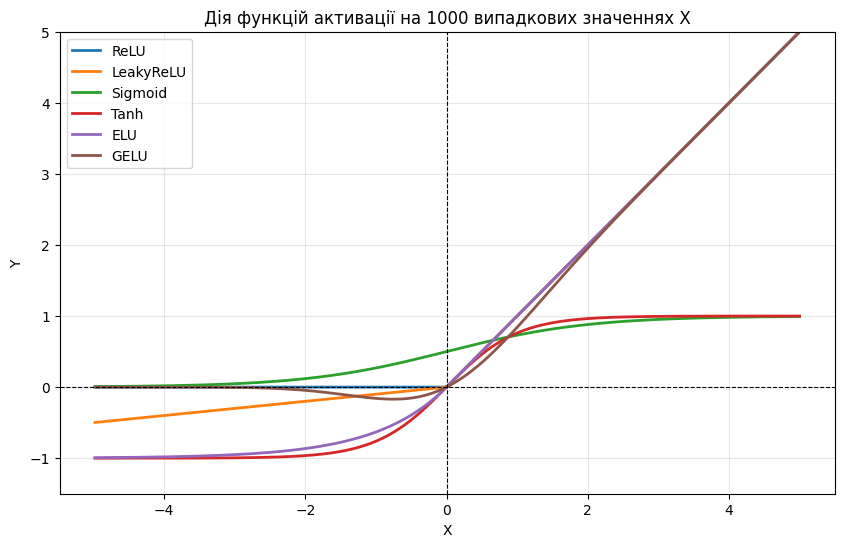

In [1]:
#Код для 5 запитання
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

torch.manual_seed(42)
x = torch.empty(1000).uniform_(-5, 5)
x_sorted, _ = torch.sort(x)

activations = {
    "ReLU": nn.ReLU(),
    "LeakyReLU": nn.LeakyReLU(0.1),
    "Sigmoid": nn.Sigmoid(),
    "Tanh": nn.Tanh(),
    "ELU": nn.ELU(),
    "GELU": nn.GELU()
}

plt.figure(figsize=(10, 6))
for name, func in activations.items():
    plt.plot(x_sorted.numpy(), func(x_sorted).numpy(), label=name, linewidth=2)

plt.axhline(0, color="black", linewidth=0.8, linestyle="--")
plt.axvline(0, color="black", linewidth=0.8, linestyle="--")
plt.title("Дія функцій активації на 1000 випадкових значеннях X")
plt.xlabel("X")
plt.ylabel("Y")
plt.legend()
plt.grid(True, alpha=0.3)
plt.ylim(-1.5, 5.0)
plt.show()

## 1.1. Визначення датасету

In [2]:
import hashlib

DATASETS = [
    "King County House Sales",
    "Diamonds",
    "Concrete Compressive Strength",
    "Auto MPG",
    "Wine Quality",
    "Laptop Price",
    "Bike Sharing Demand",
    "Ames House Prices",
    "Medical Insurance Cost",
    "Abalone",
]

FULL_NAME = "Рахімов Максим Ярославович"
dataset_index = int(
    hashlib.sha256(FULL_NAME.encode("utf-8")).hexdigest(), 16
) % len(DATASETS)
print(f"Ваш датасет (#{dataset_index + 1}):", DATASETS[dataset_index])

Ваш датасет (#6): Laptop Price


## 2.1 Підготовка даних

Крок 1. Завантаження датасету з Hugging Face

In [3]:
from datasets import load_dataset
import pandas as pd

dataset = load_dataset("Ammok/laptop_price_prediction")
print(dataset)

README.md:   0%|          | 0.00/145 [00:00<?, ?B/s]

laptops_train.csv:   0%|          | 0.00/149k [00:00<?, ?B/s]

laptops_test.csv:   0%|          | 0.00/49.6k [00:00<?, ?B/s]

Generating train split:   0%|          | 0/977 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/325 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['Manufacturer', 'Model Name', 'Category', 'Screen Size', 'Screen', 'CPU', 'RAM', ' Storage', 'GPU', 'Operating System', 'Operating System Version', 'Weight', 'Price'],
        num_rows: 977
    })
    test: Dataset({
        features: ['Manufacturer', 'Model Name', 'Category', 'Screen Size', 'Screen', 'CPU', 'RAM', ' Storage', 'GPU', 'Operating System', 'Operating System Version', 'Weight', 'Price'],
        num_rows: 325
    })
})


Крок 2. Перетворення на pandas.DataFrame

In [4]:
df = pd.concat([dataset[split].to_pandas() for split in dataset.keys()], ignore_index=True)

print(f"Розмір таблиці: {df.shape[0]} рядків, {df.shape[1]} колонок")
df.head()

Розмір таблиці: 1302 рядків, 13 колонок


,Manufacturer,Model Name,Category,Screen Size,Screen,CPU,RAM,Storage,GPU,Operating System,Operating System Version,Weight,Price
0,Apple,MacBook Pro,Ultrabook,"13.3""",IPS Panel Retina Display 2560x1600,Intel Core i5 2.3GHz,8GB,128GB SSD,Intel Iris Plus Graphics 640,macOS,None,1.37kg,11912523.48
1,Apple,Macbook Air,Ultrabook,"13.3""",1440x900,Intel Core i5 1.8GHz,8GB,128GB Flash Storage,Intel HD Graphics 6000,macOS,None,1.34kg,7993374.48
2,HP,250 G6,Notebook,"15.6""",Full HD 1920x1080,Intel Core i5 7200U 2.5GHz,8GB,256GB SSD,Intel HD Graphics 620,No OS,None,1.86kg,5112900.00
3,Apple,MacBook Pro,Ultrabook,"15.4""",IPS Panel Retina Display 2880x1800,Intel Core i7 2.7GHz,16GB,512GB SSD,AMD Radeon Pro 455,macOS,None,1.83kg,22563005.40
4,Apple,MacBook Pro,Ultrabook,"13.3""",IPS Panel Retina Display 2560x1600,Intel Core i5 3.1GHz,8GB,256GB SSD,Intel Iris Plus Graphics 650,macOS,None,1.37kg,16037611.20


Крок 3. Спліт train / val / test

In [5]:
from sklearn.model_selection import train_test_split

df.columns = df.columns.str.strip()

SEED = 42
train_df, temp_df = train_test_split(df, test_size=0.30, random_state=SEED)
val_df, test_df = train_test_split(temp_df, test_size=0.50, random_state=SEED)

print(f"Train: {train_df.shape}, Val: {val_df.shape}, Test: {test_df.shape}")

Train: (911, 13), Val: (195, 13), Test: (196, 13)


Розбиття робимо одразу до аналізу й обробки даних, щоб не допустити витоку даних data leakage. Якщо шукати викиди, заповнювати пропуски чи рахувати середні значення для масштабування на всій таблиці, то інформація з тестової вибірки вплине на навчання, і оцінка моделі на тесті буде нечесною.

Крок 4. Загальний огляд (`head`/`info`/`describe`, 1.4)

In [6]:
display(train_df.head())
print("\n--- Інформація про типи колонок ---")
print(train_df.info())
print("\n--- Описова статистика ---")
display(train_df.describe(include="all").T)

,Manufacturer,Model Name,Category,Screen Size,Screen,CPU,RAM,Storage,GPU,Operating System,Operating System Version,Weight,Price
1122,Dell,Latitude E5570,Notebook,"15.6""",1366x768,Intel Core i5 6200U 2.3GHz,4GB,500GB HDD,Intel HD Graphics 520,Linux,None,2.09kg,4656117.96
438,Lenovo,ThinkPad T470s,Ultrabook,"14.0""",2560x1440,Intel Core i7 7500U 2.7GHz,24GB,512GB SSD,Intel HD Graphics 620,Windows,10,1.32kg,21180744.00
579,Dell,Inspiron 3567,Notebook,"15.6""",Full HD 1920x1080,Intel Core i7 7500U 2.7GHz,8GB,256GB SSD,AMD Radeon R5 M430,Linux,None,2.2kg,6660196.92
842,HP,ProBook 470,Notebook,"17.3""",1600x900,Intel Core i5 7200U 2.5GHz,8GB,1TB HDD,Nvidia GeForce 930MX,Windows,10,2.63kg,8091720.00
1161,HP,Pavilion 15-cb003nv,Gaming,"15.6""",IPS Panel Full HD 1920x1080,Intel Core i7 7700HQ 2.8GHz,8GB,1TB HDD,Nvidia GeForce GTX 1050,Windows,10,2.62kg,7993908.00



--- Інформація про типи колонок ---
<class 'pandas.core.frame.DataFrame'>
Index: 911 entries, 1122 to 1126
Data columns (total 13 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Manufacturer              911 non-null    object 
 1   Model Name                911 non-null    object 
 2   Category                  911 non-null    object 
 3   Screen Size               911 non-null    object 
 4   Screen                    911 non-null    object 
 5   CPU                       911 non-null    object 
 6   RAM                       911 non-null    object 
 7   Storage                   911 non-null    object 
 8   GPU                       911 non-null    object 
 9   Operating System          911 non-null    object 
 10  Operating System Version  790 non-null    object 
 11  Weight                    911 non-null    object 
 12  Price                     911 non-null    float64
dtypes: float64(1), object(12)
mem

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Manufacturer,911,19,Lenovo,220,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Model Name,911,485,XPS 13,22,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Category,911,6,Notebook,508,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Screen Size,911,18,"15.6""",461,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Screen,911,35,Full HD 1920x1080,350,NaN,NaN,NaN,NaN,NaN,NaN,NaN
CPU,911,100,Intel Core i5 7200U 2.5GHz,123,NaN,NaN,NaN,NaN,NaN,NaN,NaN
RAM,911,9,8GB,428,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Storage,911,31,256GB SSD,282,NaN,NaN,NaN,NaN,NaN,NaN,NaN
GPU,911,97,Intel HD Graphics 620,187,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Operating System,911,7,Windows,784,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Крок 5. Перевірка пропусків

In [7]:
print("\n--- Кількість пропусків у train_df ---")
print(train_df.isnull().sum())


--- Кількість пропусків у train_df ---
Manufacturer                  0
Model Name                    0
Category                      0
Screen Size                   0
Screen                        0
CPU                           0
RAM                           0
Storage                       0
GPU                           0
Operating System              0
Operating System Version    121
Weight                        0
Price                         0
dtype: int64


Крок 6. Перевірка пропусків
Парсинг числових ознак та EDA

Оскільки у датасеті Laptop Price характеристики записані текстом, їх потрібно перетворити у числа, щоб побудувати гістограми та кореляційну матрицю.

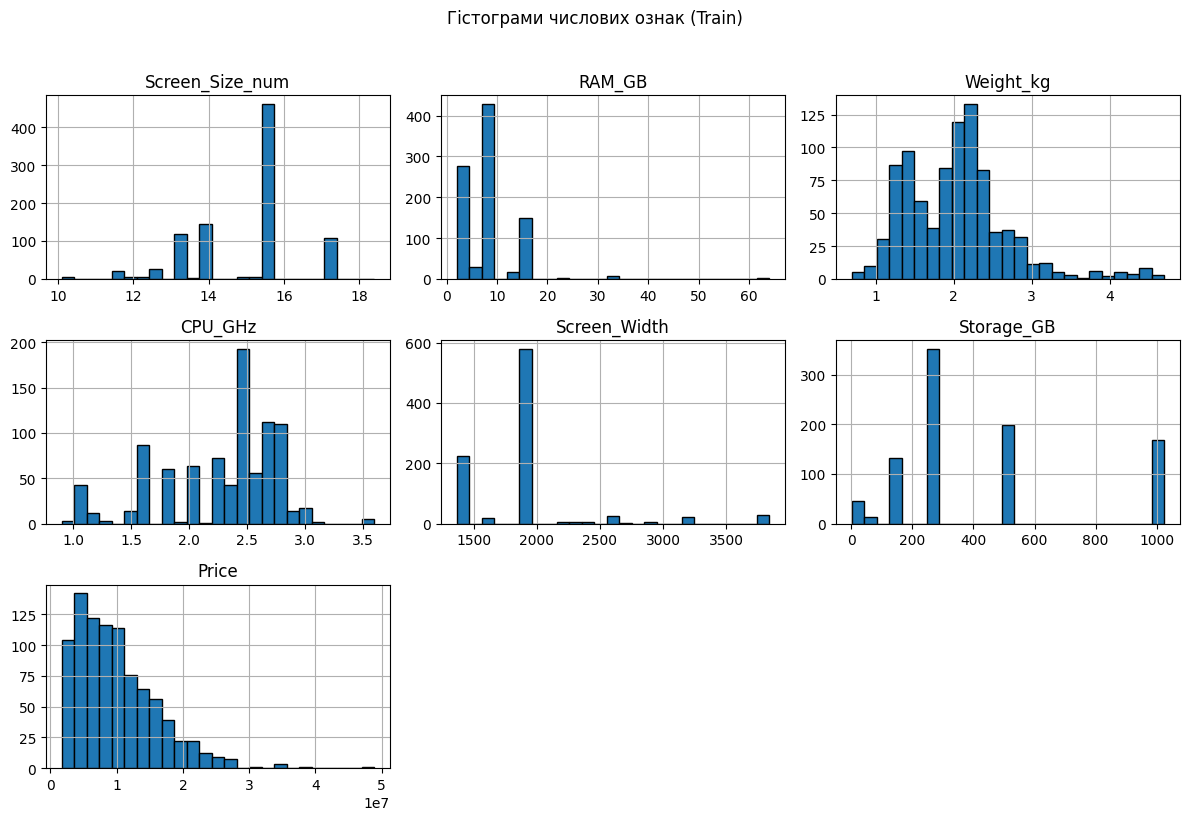

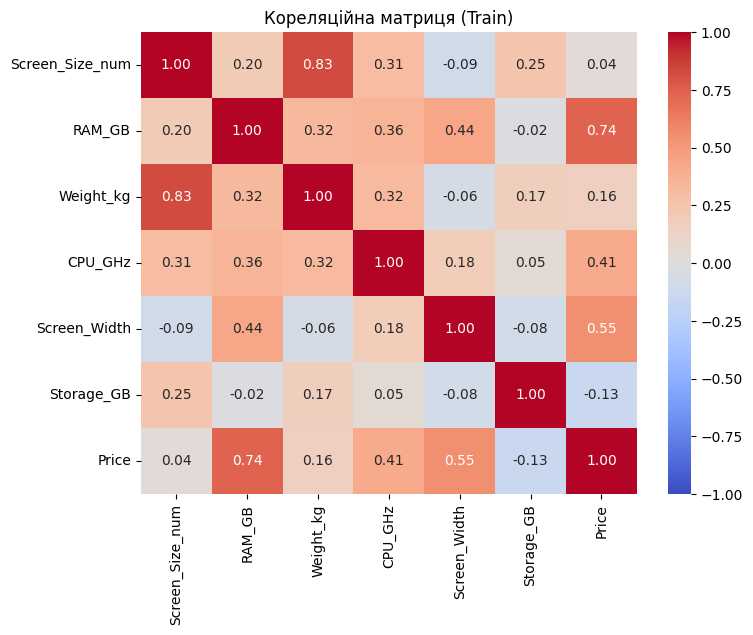

In [8]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Функція для перетворення текстових ознак у числові
def parse_laptop_features(data):
    d = data.copy()
    if "Operating System Version" in d.columns:
        d["Operating System Version"] = d["Operating System Version"].fillna("Unknown")

    d["Screen_Size_num"] = d["Screen Size"].astype(str).str.replace('"', '', regex=False).astype(float)
    d["RAM_GB"] = d["RAM"].astype(str).str.replace("GB", "", regex=False).astype(float)
    d["Weight_kg"] = d["Weight"].astype(str).str.replace("kgs", "", regex=False).str.replace("kg", "", regex=False)
    d["Weight_kg"] = pd.to_numeric(d["Weight_kg"], errors="coerce")
    d["CPU_GHz"] = d["CPU"].astype(str).str.extract(r'(\d+(?:\.\d+)?)GHz')[0].astype(float)
    d["Screen_Width"] = d["Screen"].astype(str).str.extract(r'(\d+)x\d+')[0].astype(float)

    storage_str = d["Storage"].astype(str).str.replace("1.0TB", "1024GB", regex=False).str.replace("1TB", "1024GB", regex=False)
    d["Storage_GB"] = storage_str.str.extract(r'(\d+)')[0].astype(float)

    if d["Price"].dtype == "object":
        d["Price"] = d["Price"].astype(str).str.replace(",", ".", regex=False).astype(float)

    return d

# Застосовуємо парсинг до всіх трьох вибірок окремо щоб запобігти data leakage
train_df = parse_laptop_features(train_df)
val_df = parse_laptop_features(val_df)
test_df = parse_laptop_features(test_df)

weight_median = train_df["Weight_kg"].median()
for split_df in [train_df, val_df, test_df]:
    split_df["Weight_kg"] = split_df["Weight_kg"].fillna(weight_median)

# EDA: Гістограми та кореляційна матриця
num_cols = ["Screen_Size_num", "RAM_GB", "Weight_kg", "CPU_GHz", "Screen_Width", "Storage_GB", "Price"]

train_df[num_cols].hist(figsize=(12, 8), bins=25, edgecolor="black")
plt.suptitle("Гістограми числових ознак (Train)", y=1.02)
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 6))
sns.heatmap(train_df[num_cols].corr(), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Кореляційна матриця (Train)")
plt.show()

Крок 7. Стандартизація та навчальний Baseline — Лінійна регресія

Підготовка директорій models/ і runs/, масштабування даних за допомогою StandardScaler та навчання моделі nn.Linear із записом логів у TensorBoard.

In [9]:
import os
import torch
import torch.nn as nn
from torch.utils.tensorboard import SummaryWriter
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

os.makedirs("models", exist_ok=True)
os.makedirs("runs", exist_ok=True)

feature_cols = ["Screen_Size_num", "RAM_GB", "Weight_kg", "CPU_GHz", "Screen_Width", "Storage_GB"]
TARGET_COL = "Price"

scaler = StandardScaler()
X_train = scaler.fit_transform(train_df[feature_cols])
X_val = scaler.transform(val_df[feature_cols])
X_test = scaler.transform(test_df[feature_cols])

y_train = train_df[TARGET_COL].values.reshape(-1, 1)
y_val = val_df[TARGET_COL].values.reshape(-1, 1)
y_test = test_df[TARGET_COL].values.reshape(-1, 1)

X_train_t = torch.tensor(X_train, dtype=torch.float32)
y_train_t = torch.tensor(y_train, dtype=torch.float32)
X_val_t = torch.tensor(X_val, dtype=torch.float32)
y_val_t = torch.tensor(y_val, dtype=torch.float32)
X_test_t = torch.tensor(X_test, dtype=torch.float32)
y_test_t = torch.tensor(y_test, dtype=torch.float32)

IN_FEATURES = X_train.shape[1]

# ОЧИЩУЄМО СПИСОК РЕЗУЛЬТАТІВ ВІД СТАРИХ ЕКСПЕРИМЕНТІВ
results_list = []

def train_and_evaluate(model, run_name, lr=0.01, epochs=400, optimizer_type="Adam"):
    torch.manual_seed(42)
    criterion = nn.MSELoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=lr) if optimizer_type == "Adam" else torch.optim.SGD(model.parameters(), lr=lr, momentum=0.9)
    writer = SummaryWriter(log_dir=f"runs/{run_name}")

    for epoch in range(epochs):
        model.train()
        optimizer.zero_grad()
        preds = model(X_train_t)
        loss = criterion(preds, y_train_t)
        loss.backward()
        optimizer.step()

        model.eval()
        with torch.no_grad():
            val_preds = model(X_val_t)
            val_loss = criterion(val_preds, y_val_t)

        writer.add_scalar("Loss/train", loss.item(), epoch)
        writer.add_scalar("Loss/val", val_loss.item(), epoch)

    writer.close()
    torch.save(model.state_dict(), f"models/{run_name}.pt")

    model.eval()
    with torch.no_grad():
        test_preds = model(X_test_t).numpy()

    mse = mean_squared_error(y_test, test_preds)
    rmse = np.sqrt(mse)
    mae = mean_absolute_error(y_test, test_preds)
    r2 = r2_score(y_test, test_preds)

    results_list.append({"model": run_name, "MSE": round(mse, 2), "RMSE": round(rmse, 2), "MAE": round(mae, 2), "R2": round(r2, 4)})
    print(f"[{run_name}] Test R2: {r2:.4f} | RMSE: {rmse:.2f}")

# 1. Baseline: Лінійна регресія
linear_model = nn.Linear(IN_FEATURES, 1)
train_and_evaluate(linear_model, run_name="linear", lr=0.01, epochs=300)

[linear] Test R2: -2.0791 | RMSE: 12188898.11


Крок 8. Нейромережі та підбір гіперпараметрів

Потрібно натренувати щонайменше 5 варіантів моделей (1 лінійна + 2 архітектури + 2 варіанти гіперпараметрів) та зберегти таблицю results.csv

In [10]:
# 2. Нейромережа v1 (64 -> 32, ReLU)
nn_v1 = nn.Sequential(
    nn.Linear(IN_FEATURES, 64),
    nn.ReLU(),
    nn.Linear(64, 32),
    nn.ReLU(),
    nn.Linear(32, 1)
)
train_and_evaluate(nn_v1, run_name="nn_v1", lr=0.005, epochs=300)

# 3. Нейромережа v2 (128 -> 64 -> 32, LeakyReLU) — яка вже показала найкращий результат
nn_v2 = nn.Sequential(
    nn.Linear(IN_FEATURES, 128),
    nn.LeakyReLU(0.1),
    nn.Linear(128, 64),
    nn.LeakyReLU(0.1),
    nn.Linear(64, 32),
    nn.LeakyReLU(0.1),
    nn.Linear(32, 1)
)
train_and_evaluate(nn_v2, run_name="nn_v2", lr=0.005, epochs=300)

# 4. Тюнінг (lr=0.001)
nn_v2_lr = nn.Sequential(
    nn.Linear(IN_FEATURES, 128),
    nn.LeakyReLU(0.1),
    nn.Linear(128, 64),
    nn.LeakyReLU(0.1),
    nn.Linear(64, 32),
    nn.LeakyReLU(0.1),
    nn.Linear(32, 1)
)
train_and_evaluate(nn_v2_lr, run_name="nn_v2_lr_0.001", lr=0.001, epochs=300)

# 5. Тюнінг (епохи = 600)
nn_v2_epochs = nn.Sequential(
    nn.Linear(IN_FEATURES, 128),
    nn.LeakyReLU(0.1),
    nn.Linear(128, 64),
    nn.LeakyReLU(0.1),
    nn.Linear(64, 32),
    nn.LeakyReLU(0.1),
    nn.Linear(32, 1)
)
train_and_evaluate(nn_v2_epochs, run_name="nn_v2_epochs_600", lr=0.001, epochs=600)

# Зведення та збереження чистих результатів у results.csv
results_df = pd.DataFrame(results_list).sort_values(by="RMSE")
results_df.to_csv("results.csv", index=False)
display(results_df)

[nn_v1] Test R2: -2.0487 | RMSE: 12128544.06
[nn_v2] Test R2: 0.5606 | RMSE: 4604343.30
[nn_v2_lr_0.001] Test R2: -2.0625 | RMSE: 12155958.24
[nn_v2_epochs_600] Test R2: -1.7642 | RMSE: 11548847.20


,model,MSE,RMSE,MAE,R2
2,nn_v2,2.119998e+13,4604343.30,3519030.09,0.5606
4,nn_v2_epochs_600,1.333759e+14,11548847.20,9517057.37,-1.7642
1,nn_v1,1.471016e+14,12128544.06,9966554.03,-2.0487
3,nn_v2_lr_0.001,1.477673e+14,12155958.24,9989104.36,-2.0625
0,linear,1.485692e+14,12188898.11,10015896.72,-2.0791


Крок 9. Gradio-застосунок

In [11]:
import gradio as gr

trained_models = {
    "Linear": linear_model,
    "NN v1 (2 layers)": nn_v1,
    "NN v2 (3 layers)": nn_v2,
    "NN v2 (lr=100)": nn_v2_lr,
    "NN v2 (800 epochs)": nn_v2_epochs,
}

def predict_price(*features):
    x_input = np.array(features, dtype=np.float32).reshape(1, -1)
    x_scaled = scaler.transform(x_input)
    x_tensor = torch.tensor(x_scaled, dtype=torch.float32)

    preds = {}
    for name, model in trained_models.items():
        model.eval()
        with torch.no_grad():
            preds[name] = round(model(x_tensor).item(), 2)

    return pd.DataFrame(list(preds.items()), columns=["Модель", "Прогнозована ціна"])

inputs = [
    gr.Slider(float(train_df[col].min()), float(train_df[col].max()), float(train_df[col].median()), label=col)
    for col in feature_cols
]

demo = gr.Interface(
    fn=predict_price,
    inputs=inputs,
    outputs=gr.Dataframe(label="Порівняння прогнозів"),
    title="Laptop Price Predictor"
)

demo.launch(share=False)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
Note: opening Chrome Inspector may crash demo inside Colab notebooks.
* To create a public link, set `share=True` in `launch()`.


<IPython.core.display.Javascript object>